In [1]:
# ===================== CELL 1 =====================
!apt-get -qq install -y tesseract-ocr > /dev/null
!pip -q install pytesseract keybert sentence-transformers gradio



In [3]:
   !rm -f *.jpg *.jpeg *.png *.xlsx *.csv

Saving ground_truth_keywords.xlsx to ground_truth_keywords.xlsx
Saving notice6.jpg to notice6.jpg
Saving notice7.jpg to notice7.jpg
Saving notice8.jpg to notice8.jpg
Saving notice9.jpg to notice9.jpg
Saving notice10.jpg to notice10.jpg
Saving notice11.jpg to notice11.jpg
Saving notice12.jpg to notice12.jpg
Saving notice1.jpg to notice1.jpg
Saving notice2.jpg to notice2.jpg
Saving notice3.jpg to notice3.jpg
Saving notice4.jpg to notice4.jpg
Saving notice5.jpg to notice5.jpg
12 images | ground truth: ground_truth_keywords.xlsx
EASTERN INSTITUTE OF TECHNOLOGY AND MANAGEMENT

(Approved by AICTE, Affiliated to BPUT)
Bhubaneswar, Odisha - 751024

Ref. No.: EITM/COE/114/2026 Date: 02 November 2026

END SEMESTER EXAMINATION - TIMETABLE

To: All B.Tech Students

The End Semester Examinations for all B.Tech programmes will
commence on 25 November 2026. The detailed timetable is available on
the college portal and the notice board.

Students must download their hall ticket from the portal from 18

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

TF-IDF : ['examination', 'hall', 'hall ticket', 'timetable', 'ticket', 'end', 'end semester', 'portal', 'tech', 'november']
KeyBERT: ['examination timetable', 'semester examinations', 'examination hall', 'timetable available', 'end semester', 'november examination', 'examination section', 'examinations tech', 'college portal', 'tech programmes']
12 notices matched | unmatched: none
         precision  recall     f1
method                           
keybert      0.502   0.676  0.571
tfidf        0.671   0.535  0.587 

method    keybert  tfidf
category                
event       0.511  0.507
exam        0.556  0.634
fee         0.585  0.571
holiday     0.631  0.635


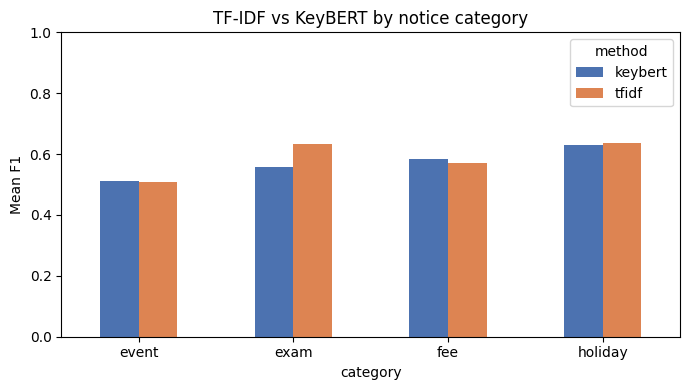

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://168e20b599b4e99280.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://168e20b599b4e99280.gradio.live


In [6]:

from google.colab import files
uploaded = files.upload()

# Colab renames re-uploaded files to 'name (1).jpg' -> restore the original names
import os, re
fixed = {}
for n, data in uploaded.items():
    clean = re.sub(r' \(\d+\)(?=\.\w+$)', '', n)
    if clean != n:
        with open(clean, 'wb') as f: f.write(data)
        os.remove(n)
    fixed[clean] = data
uploaded = fixed

names = sorted(n for n in uploaded if n.lower().endswith(('.jpg', '.jpeg', '.png')))
gt_name = next(n for n in uploaded if n.lower().endswith(('.xlsx', '.csv')))
print(len(names), 'images | ground truth:', gt_name)

# ===================== CELL 3 =====================
import cv2, pytesseract

def ocr_image(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)                                       # grayscale
    gray = cv2.fastNlMeansDenoising(gray)                                              # remove scan noise
    _, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)           # Otsu binarisation
    return pytesseract.image_to_string(bw)                                             # Tesseract OCR

raw_texts = [ocr_image(cv2.imread(n)) for n in names]
print(raw_texts[0])

# ===================== CELL 4 =====================
import re
from collections import Counter
from difflib import get_close_matches

def get_lines(text):
    return [l.strip() for l in text.splitlines() if l.strip()]

line_count = Counter(l.lower() for t in raw_texts for l in set(get_lines(t)))
LETTERHEAD = {l for l, c in line_count.items() if c >= len(raw_texts) / 2}
print('Letterhead lines removed:', LETTERHEAD)

def is_letterhead(line):
    # fuzzy match (>=85% similar) so small OCR errors like 'Copy ta' or '{Approved' are still caught
    return bool(get_close_matches(line.lower(), LETTERHEAD, n=1, cutoff=0.85)) or re.match(r'ref\W', line, re.I)

def remove_letterhead(text):
    return '\n'.join(l for l in get_lines(text) if not is_letterhead(l))

def clean_text(text):
    text = re.sub(r'[^A-Za-z\s]', ' ', text)           # keep letters only
    return re.sub(r'\s+', ' ', text).strip().lower()    # single spaces, lowercase

corpus      = [clean_text(t) for t in raw_texts]                       # full text -> TF-IDF (IDF handles letterhead itself)
corpus_body = [clean_text(remove_letterhead(t)) for t in raw_texts]   # body only -> KeyBERT
print(corpus_body[0])

# ===================== CELL 5 =====================
from sklearn.feature_extraction.text import TfidfVectorizer
from keybert import KeyBERT

# TF-IDF: statistical baseline (rare-in-corpus but frequent-in-document terms)
vec = TfidfVectorizer(stop_words='english', ngram_range=(1, 2))
matrix = vec.fit_transform(corpus)
terms = vec.get_feature_names_out()

def tfidf_keywords(i, n=10):
    row = matrix[i].toarray()[0]
    return [terms[j] for j in row.argsort()[::-1][:n] if row[j] > 0]

# KeyBERT: semantic (phrases whose embedding is closest to the whole notice)
kw_model = KeyBERT('all-MiniLM-L6-v2')   # https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2

def keybert_keywords(doc, n=10):
    result = kw_model.extract_keywords(doc, keyphrase_ngram_range=(1, 2), stop_words='english',
                                       use_mmr=True, diversity=0.3, top_n=n)   # MMR avoids near-duplicate phrases
    return [k for k, score in result]

print('TF-IDF :', tfidf_keywords(0))
print('KeyBERT:', keybert_keywords(corpus_body[0]))

# ===================== CELL 6 =====================
import pandas as pd

df = pd.DataFrame({'file':    names,
                   'tfidf':   [', '.join(tfidf_keywords(i)) for i in range(len(names))],
                   'keybert': [', '.join(keybert_keywords(d)) for d in corpus_body]})
df.to_csv('keywords.csv', index=False)
df

# ===================== CELL 7 =====================
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

gt = pd.read_csv(gt_name) if gt_name.endswith('.csv') else pd.read_excel(gt_name)
gt.columns = [c.strip().lower() for c in gt.columns]
gt = gt.rename(columns={'file name': 'file', 'keywords': 'truth'})
merged = df.merge(gt[['file', 'category', 'truth']], on='file')
print(len(merged), 'notices matched | unmatched:', set(df['file']) - set(gt['file']) or 'none')
assert len(merged) > 0, 'No file names match the ground-truth sheet - check the image names'

def to_words(text):
    text = re.sub(r'[^a-z\s]', ' ', str(text).lower())
    return {w for w in text.split() if w not in ENGLISH_STOP_WORDS and len(w) > 1}

def prf(pred, truth):
    p, t = to_words(pred), to_words(truth)
    hit = len(p & t)
    precision = hit / len(p) if p else 0
    recall = hit / len(t) if t else 0
    f1 = 2 * precision * recall / (precision + recall) if hit else 0
    return precision, recall, f1

res = pd.DataFrame([{'file': r['file'], 'category': r['category'], 'method': m,
                     **dict(zip(['precision', 'recall', 'f1'], prf(r[m], r['truth'])))}
                    for _, r in merged.iterrows() for m in ['tfidf', 'keybert']])

summary = res.groupby('method')[['precision', 'recall', 'f1']].mean().round(3)
by_cat = res.groupby(['category', 'method'])['f1'].mean().round(3).unstack()
print(summary, '\n')
print(by_cat)

res.to_csv('evaluation_results.csv', index=False)
summary.to_csv('evaluation_summary.csv')

# ===================== CELL 8 =====================
import matplotlib.pyplot as plt

ax = by_cat.plot(kind='bar', figsize=(7, 4), rot=0, color=['#4C72B0', '#DD8452'])
ax.set_ylabel('Mean F1'); ax.set_ylim(0, 1); ax.set_title('TF-IDF vs KeyBERT by notice category')
plt.tight_layout(); plt.savefig('f1_by_category.png', dpi=150); plt.show()

for f in ['keywords.csv', 'evaluation_results.csv', 'evaluation_summary.csv', 'f1_by_category.png']:
    files.download(f)

# ===================== CELL 9 =====================
import gradio as gr

def extract(img_rgb):
    text = ocr_image(cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR))
    row = vec.transform([clean_text(text)]).toarray()[0]
    tfidf_df = pd.DataFrame([(terms[j], round(row[j], 3)) for j in row.argsort()[::-1][:10] if row[j] > 0],
                            columns=['term', 'tfidf score'])
    kb = kw_model.extract_keywords(clean_text(remove_letterhead(text)), keyphrase_ngram_range=(1, 2),
                                   stop_words='english', use_mmr=True, diversity=0.3, top_n=10)
    keybert_df = pd.DataFrame([(k, round(s, 3)) for k, s in kb], columns=['keyphrase', 'similarity'])
    return text, keybert_df, tfidf_df

gr.Interface(fn=extract,
             inputs=gr.Image(type='numpy', label='Scanned notice'),
             outputs=[gr.Textbox(label='OCR text', lines=12),
                      gr.Dataframe(label='KeyBERT keyphrases'),
                      gr.Dataframe(label='TF-IDF keywords')],
             title='Keyword Extraction from Scanned Notices',
             examples=[[n] for n in names[:3]]).launch(share=True, debug=True)

